# 01 · Análise exploratória do BreakHis

Etapa 2 do `PROJETO.md`. Objetivos:

1. Conferir contagens (imagens, pacientes, magnificações).
2. **Apresentar as anomalias de identificação de paciente** encontradas na base (seções 2 e 3), sem decidir ainda como tratá-las.
3. Medir imagens por paciente × magnificação e a **viabilidade dos k-shots** no protocolo por paciente (P1, P3 e P4 do `PROJETO.md`).
4. Ver imagens do mesmo paciente lado a lado.

Pré-requisito: `uv run python scripts/build_csv.py` (gera `data/breakhis.csv`).

Duas leituras de "paciente" convivem neste notebook:
- **`paciente`**: o ID oficial, igual ao nome da pasta (ex. `14-22549AB`), que dá os 82 pacientes do artigo da base;
- **`caso`**: o mesmo ID sem as letras de seção (ex. `14-22549`), que junta pastas com o mesmo número de lâmina.

In [1]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
df = pd.read_csv(DATA / "breakhis.csv")

# ordem: seen (DC, F, MC, TA), unseen da meta-validação (A, LC), unseen do meta-teste (PT, PC) — D2
SUBTIPOS = ["DC", "F", "MC", "TA", "A", "LC", "PT", "PC"]
PAPEL = dict(DC="seen", F="seen", MC="seen", TA="seen", A="unseen mval", LC="unseen mval", PT="unseen mtst", PC="unseen mtst")
MAGS = [40, 100, 200, 400]


def show(paths, titles, ncols, size=2.6):
    """Grade de imagens (caminhos relativos a data/)."""
    nrows = -(-len(paths) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size * 1.5, nrows * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, p, t in zip(axes.flat, paths, titles):
        img = Image.open(DATA / p)
        img.thumbnail((350, 350))
        ax.imshow(img)
        ax.set_title(t, fontsize=8)
    plt.tight_layout()
    plt.show()


len(df)

7909

## 1. Visão geral

In [2]:
pd.crosstab(df.subtipo, df.magnificacao, margins=True, margins_name="total").loc[SUBTIPOS + ["total"]]

magnificacao,40,100,200,400,total
subtipo,,,,,
DC,864,903,896,788,3451
F,253,260,264,237,1014
MC,205,222,196,169,792
TA,149,150,140,130,569
A,114,113,111,106,444
LC,156,170,163,137,626
PT,109,121,108,115,453
PC,145,142,135,138,560
total,1995,2081,2013,1820,7909


In [3]:
resumo = df.groupby("subtipo").agg(
    classe=("classe", "first"),
    imagens=("path", "size"),
    pastas=("paciente", "nunique"),
    casos=("caso", "nunique"),
).loc[SUBTIPOS]
resumo.insert(1, "papel", resumo.index.map(PAPEL))
print("pares (subtipo, pasta):", df.groupby(["subtipo", "paciente"]).ngroups,
      "| IDs de pasta distintos:", df.paciente.nunique(),
      "| casos distintos:", df.caso.nunique())
resumo

pares (subtipo, pasta): 82 | IDs de pasta distintos: 81 | casos distintos: 70


,classe,papel,imagens,pastas,casos
subtipo,,,,,
DC,M,seen,3451,38,38
F,B,seen,1014,10,7
MC,M,seen,792,9,7
TA,B,seen,569,7,6
A,B,unseen mval,444,4,2
LC,M,unseen mval,626,5,4
PT,B,unseen mtst,453,3,3
PC,M,unseen mtst,560,6,6


## 2. Anomalia A: imagens idênticas pixel a pixel

Comparar os arquivos byte a byte não acha duplicatas (o PNG foi regravado), então
comparamos o **conteúdo em pixels**: um hash MD5 da matriz RGB de cada imagem.
No mesmo laço guardamos a **cor média** (R, G, B) de cada imagem, usada na seção 3.

Leva cerca de 1 minuto (lê as 7.909 imagens).

In [4]:
def pixel_stats(path):
    a = np.asarray(Image.open(DATA / path).convert("RGB"))
    return hashlib.md5(a.tobytes()).hexdigest(), *a.reshape(-1, 3).mean(0)

df[["hash", "r", "g", "b"]] = pd.DataFrame([pixel_stats(p) for p in df.path], index=df.index)
dup = df[df.duplicated("hash", keep=False)].sort_values(["hash", "subtipo"])
print(f"{dup.hash.nunique()} grupos de imagens repetidas, {len(dup)} arquivos envolvidos")
dup.groupby(["subtipo", "paciente"]).size().rename("arquivos repetidos")

125 grupos de imagens repetidas, 250 arquivos envolvidos


subtipo  paciente
DC       14-13412    123
LC       14-12204      4
         14-13412    123
Name: arquivos repetidos, dtype: int64

### A.1 · `14-13412`: o mesmo paciente rotulado como DC **e** como LC

As 123 imagens da pasta `SOB_M_DC_14-13412` reaparecem em `SOB_M_LC_14-13412`
(às vezes com outro número de sequência). Abaixo, pares DC × LC com o mesmo conteúdo.

pares DC×LC idênticos: 123


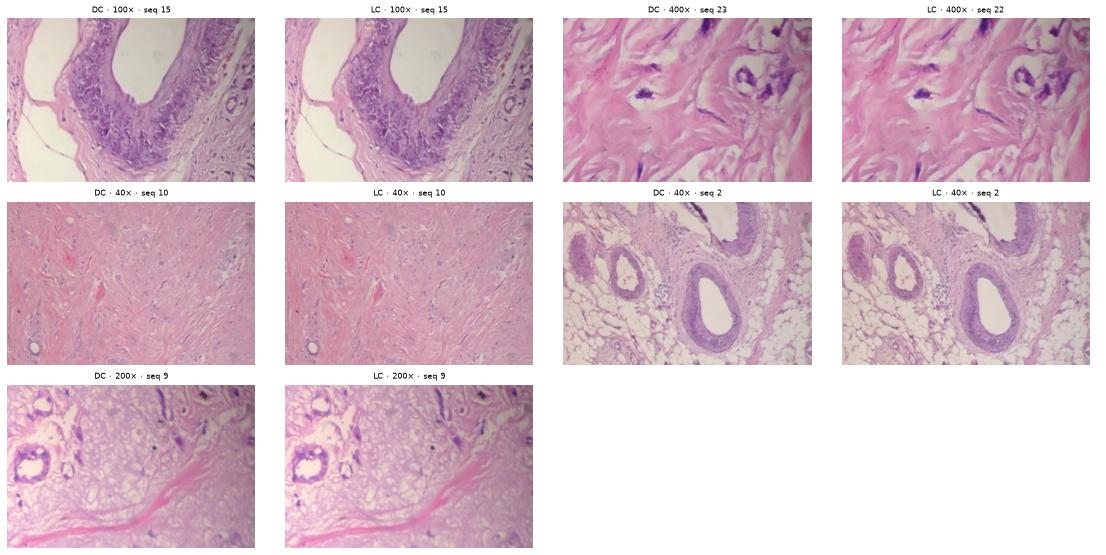

In [5]:
par = dup[dup.paciente == "14-13412"].groupby("hash").filter(lambda g: set(g.subtipo) == {"DC", "LC"})
print("pares DC×LC idênticos:", par.hash.nunique())
amostra = par[par.hash.isin(par.hash.unique()[::30])]  # alguns pares espalhados
show(amostra.path.tolist(), [f"{r.subtipo} · {r.magnificacao}× · seq {r.seq}" for r in amostra.itertuples()], ncols=4)

### A.2 · Repetições dentro de um mesmo paciente

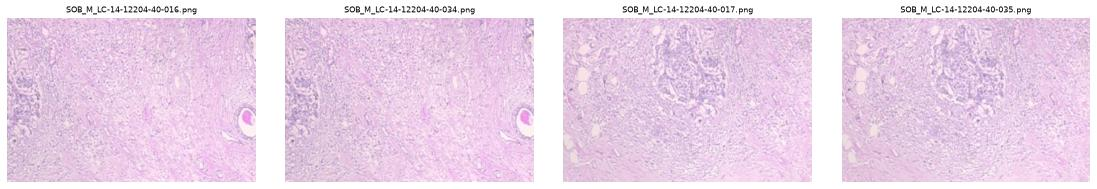

,path,subtipo,paciente,magnificacao,seq
6029,BreaKHis_v1/histology_slides/breast/malignant/...,LC,14-12204,40,16
6032,BreaKHis_v1/histology_slides/breast/malignant/...,LC,14-12204,40,34
6030,BreaKHis_v1/histology_slides/breast/malignant/...,LC,14-12204,40,17
6033,BreaKHis_v1/histology_slides/breast/malignant/...,LC,14-12204,40,35


In [6]:
outros = dup[dup.paciente != "14-13412"]
show(outros.path.tolist(), [Path(p).name for p in outros.path], ncols=4)
outros[["path", "subtipo", "paciente", "magnificacao", "seq"]]

## 3. Anomalia B: pastas diferentes com o mesmo número de lâmina

O README da base define o ID como `ano-lâmina` seguido de **letras de seção**
(`<SLIDE_ID>::=<NUMBER><SECTION>`). Várias pastas compartilham o número e diferem só
nas letras; em dois casos, até o subtipo muda.

In [7]:
pastas = df.groupby(["caso", "subtipo", "paciente"]).size().rename("imagens").reset_index()
multi = pastas[pastas.groupby("caso").paciente.transform("nunique") > 1]
multi.assign(varios_subtipos=multi.groupby("caso").subtipo.transform("nunique") > 1)

,caso,subtipo,paciente,imagens,varios_subtipos
16,14-14134,F,14-14134,142,False
17,14-14134,F,14-14134E,94,False
21,14-15570,LC,14-15570,201,False
22,14-15570,LC,14-15570C,125,False
28,14-16184,TA,14-16184,132,False
29,14-16184,TA,14-16184CD,124,False
42,14-18842,MC,14-18842,62,False
43,14-18842,MC,14-18842D,64,False
46,14-19979,MC,14-19979,98,False
47,14-19979,MC,14-19979C,62,False


### B.1 · Uma imagem de cada pasta (100×)

Cada linha é um caso; cada coluna, uma pasta. As duas últimas linhas são **controle**:
pastas de casos diferentes do mesmo subtipo.

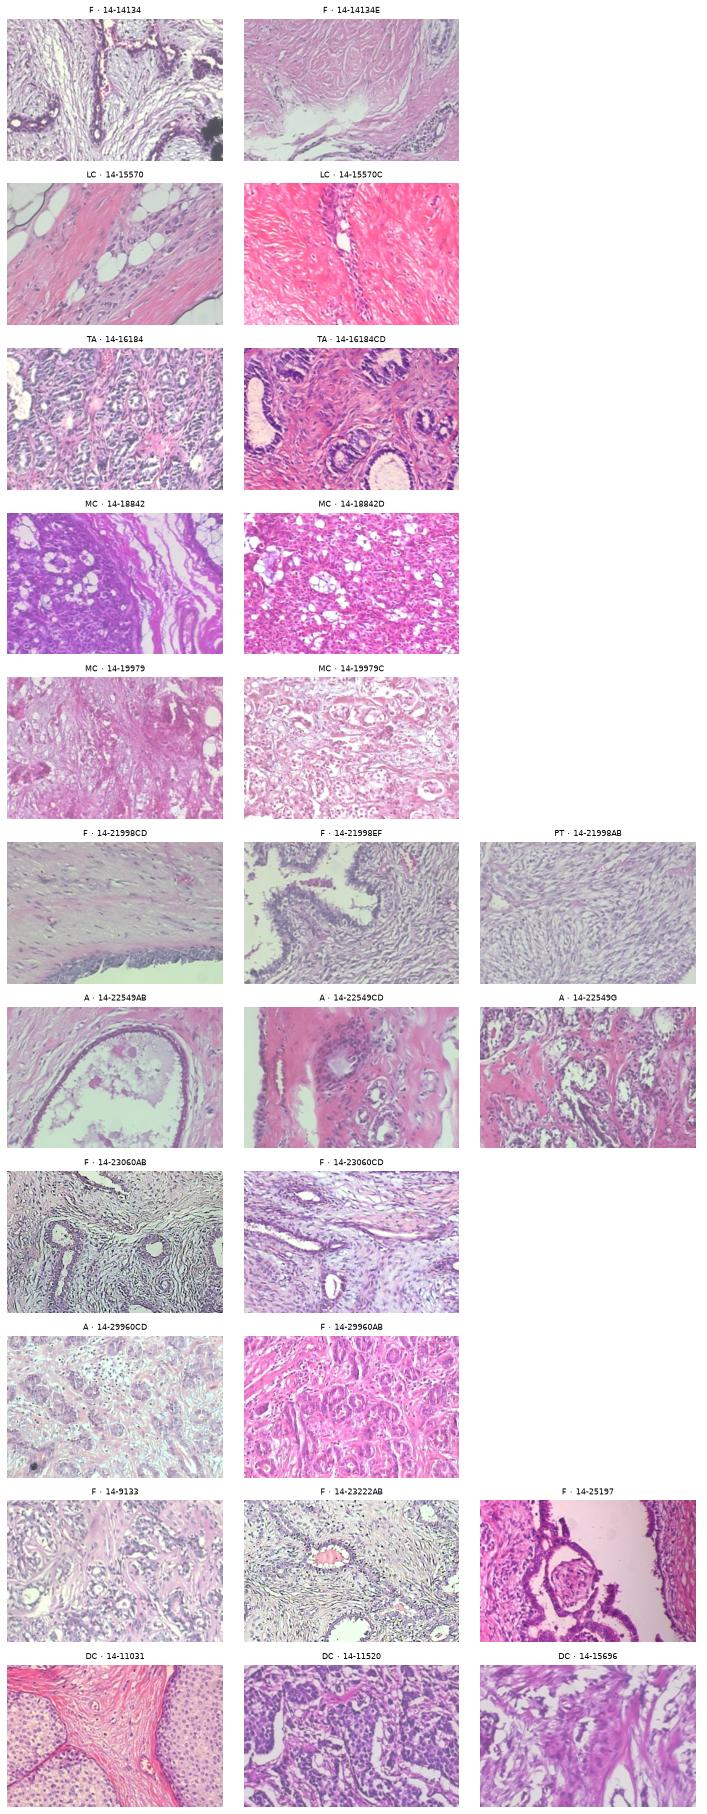

In [8]:
rng = np.random.default_rng(0)
m100 = df[df.magnificacao == 100]
linhas = [g.paciente.tolist() for _, g in multi.groupby("caso")]
simples = pastas[~pastas.caso.isin(multi.caso)]  # controle: só casos com uma única pasta
linhas += [rng.choice(simples[simples.subtipo == s].paciente.unique(), 3, replace=False).tolist() for s in ["F", "DC"]]
paths, titles = [], []
for linha in linhas:
    for col in range(3):
        if col < len(linha):
            r = m100[m100.paciente == linha[col]].iloc[0]
            paths.append(r.path); titles.append(f"{r.subtipo} · {r.paciente}")
        else:
            paths.append(None); titles.append("")
fig, axes = plt.subplots(len(linhas), 3, figsize=(10, 2.3 * len(linhas)))
for ax, p, t in zip(axes.flat, paths, titles):
    ax.axis("off")
    if p:
        img = Image.open(DATA / p); img.thumbnail((350, 350)); ax.imshow(img); ax.set_title(t, fontsize=8)
plt.tight_layout(); plt.show()

### B.2 · Indício quantitativo: cor média por pasta

Sem anotação extra não dá para **provar** que duas pastas são do mesmo paciente.
Um indício: lâminas da mesma peça costumam ter coloração H&E parecida. Calculamos a
cor média de cada pasta (média das imagens) e a distância entre todos os pares de pastas.

Se as pastas com o mesmo número fossem pacientes independentes, suas distâncias
estariam espalhadas como as dos demais pares. Se ficarem concentradas no início da
distribuição, é um indício (não uma prova) de mesma origem.

In [9]:
pasta = df.groupby(["subtipo", "paciente"]).agg(caso=("caso", "first"), r=("r", "mean"), g=("g", "mean"), b=("b", "mean")).reset_index()
pasta = pasta[pasta.paciente != "14-13412"]  # duplicado (anomalia A) — fora desta comparação
X = pasta[["r", "g", "b"]].to_numpy()
i, j = np.triu_indices(len(pasta), 1)
d = pd.DataFrame({
    "a": pasta.paciente.to_numpy()[i], "b": pasta.paciente.to_numpy()[j],
    "mesmo_caso": pasta.caso.to_numpy()[i] == pasta.caso.to_numpy()[j],
    "mesmo_subtipo": pasta.subtipo.to_numpy()[i] == pasta.subtipo.to_numpy()[j],
    "dist": np.linalg.norm(X[i] - X[j], axis=1),
})
d["percentil"] = d.dist.rank(pct=True).mul(100).round(1)  # % de todos os pares com distância menor ou igual
print(d.groupby("mesmo_caso").dist.describe().round(1))
d[d.mesmo_caso].sort_values("dist")

             count  mean   std  min   25%   50%   75%    max
mesmo_caso                                                  
False       3147.0  37.7  19.1  0.8  23.6  35.1  50.2  119.7
True          13.0  22.4  14.5  1.1  12.9  18.4  32.3   53.7


,a,b,mesmo_caso,mesmo_subtipo,dist,percentil
0,14-22549AB,14-22549CD,True,True,1.057582,0.1
2494,14-21998CD,14-21998EF,True,True,4.869635,0.8
2520,14-21998CD,14-21998AB,True,False,12.843279,6.7
2555,14-21998EF,14-21998AB,True,False,12.855818,6.8
2419,14-14134,14-14134E,True,True,14.301217,9.1
79,14-22549CD,14-22549G,True,True,17.392673,14.6
1,14-22549AB,14-22549G,True,True,18.372105,15.7
2970,14-18842,14-18842D,True,True,24.061543,25.9
2565,14-23060AB,14-23060CD,True,True,28.196662,35.5
3007,14-19979,14-19979C,True,True,32.314580,44.6


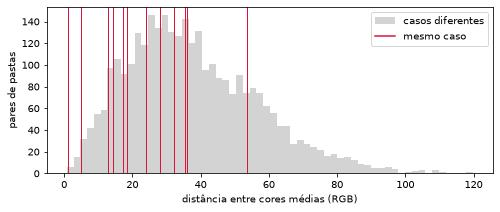

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(d[~d.mesmo_caso].dist, bins=60, color="lightgray", label="casos diferentes")
for x in d[d.mesmo_caso].dist:
    ax.axvline(x, color="crimson", lw=1)
ax.plot([], [], color="crimson", label="mesmo caso")
ax.set_xlabel("distância entre cores médias (RGB)"); ax.set_ylabel("pares de pastas"); ax.legend()
plt.show()

## 4. Imagens por paciente × magnificação

Para cada subtipo e magnificação: quantos pacientes há e o mínimo, a mediana e o
máximo de imagens por paciente, nas duas leituras de "paciente".

In [11]:
def por_unidade(unidade):
    n = df.groupby(["subtipo", unidade, "magnificacao"]).size()
    t = n.groupby(["subtipo", "magnificacao"]).agg(n="count", min="min", mediana="median", max="max")
    t = t.unstack("magnificacao").reindex(SUBTIPOS).swaplevel(axis=1)
    return t[[(m, c) for m in MAGS for c in ["n", "min", "mediana", "max"]]]

por_unidade("paciente")

magnificacao 40                  100                 200                 400  \
               n min mediana max   n min mediana max   n min mediana max   n   
subtipo                                                                        
DC            38   1    23.0  39  38  10    22.5  42  38   9    21.5  62  38   
F             10  14    24.5  37  10  11    31.0  36  10  16    25.0  38  10   
MC             9  15    17.0  46   9  12    22.0  50   9  14    21.0  47   9   
TA             7  12    16.0  39   7  14    17.0  37   7  12    17.0  35   7   
A              4  15    32.0  35   4  13    32.0  36   4  16    31.5  32   4   
LC             5  20    31.0  51   5  17    33.0  54   5  18    30.0  55   5   
PT             3  13    38.0  58   3  16    39.0  66   3  14    42.0  52   3   
PC             6  17    22.0  35   6  16    21.5  38   6  14    20.0  33   6   

magnificacao                  
             min mediana max  
subtipo                       
DC             8    21.0  38  
F             12    22.0  37  
MC             9    16.0  35  
TA            14    16.0  29  
A             17    29.5  30  
LC            17    26.0  41  
PT            17    39.0  59  
PC            13    19.5  36

In [12]:
por_unidade("caso")

magnificacao 40                  100                  200                 400  \
               n min mediana max   n min mediana  max   n min mediana max   n   
subtipo                                                                         
DC            38   1    23.0  39  38  10    22.5   42  38   9    21.5  62  38   
F              7  17    26.0  68   7  15    33.0   64   7  17    34.0  66   7   
MC             7  15    29.0  46   7  12    38.0   50   7  14    23.0  47   7   
TA             6  12    16.0  74   6  14    16.5   71   6  12    16.5  58   6   
A              2  15    57.0  99   2  13    56.5  100   2  16    55.5  95   2   
LC             4  20    27.0  82   4  17    32.0   89   4  18    30.0  85   4   
PT             3  13    38.0  58   3  16    39.0   66   3  14    42.0  52   3   
PC             6  17    22.0  35   6  16    21.5   38   6  14    20.0  33   6   

magnificacao                  
             min mediana max  
subtipo                       
DC             8    21.0  38  
F             17    33.0  60  
MC            11    25.0  39  
TA            14    15.5  53  
A             17    53.0  89  
LC            17    25.0  70  
PT            17    39.0  59  
PC            13    19.5  36

In [13]:
cobertura = df.groupby(["subtipo", "paciente"]).magnificacao.nunique()
print("pastas sem as 4 magnificações:", (cobertura < 4).sum())
cobertura[cobertura < 4]

pastas sem as 4 magnificações: 0


Series([], Name: magnificacao, dtype: int64)

## 5. Viabilidade dos k-shots no protocolo por paciente (P-PAC)

Simulação do sorteio planejado na seção 6.3 do `PROJETO.md`, por classe e magnificação:
embaralhar os pacientes, colocá-los no support até somar **k** imagens e exigir que os
pacientes **restantes** tenham pelo menos **k_tst = 15** imagens para o query.
O valor é a fração de 1.000 sorteios em que isso funciona (1,00 = sempre viável).

- **Classes unseen** (A, LC, PT, PC): usam todos os pacientes da classe, porque
  aparecem numa etapa só.
- **Classes seen** (DC, F, MC, TA): a divisão entre etapas ainda não existe. Usamos o
  tamanho previsto para mval/mtst, **20% dos pacientes da classe, com mínimo de 2**
  (ex.: DC → 8, TA → 2), sorteados ao acaso a cada repetição.

No P-IMG basta a classe ter k + 15 imagens na etapa, o que sempre ocorre.

In [14]:
K, K_TST = [1, 5, 10, 20], 15


def viavel(contagens, k, n_pac=None, n=1000, seed=0):
    """Fração de sorteios em que support (≥ k imagens) e query (≥ K_TST) cabem em pacientes disjuntos."""
    rng = np.random.default_rng(seed)
    ok = 0
    for _ in range(n):
        c = rng.permutation(contagens)[:n_pac]
        i = np.searchsorted(np.cumsum(c), k)  # primeiro paciente com o support completo
        ok += i < len(c) and c[i + 1:].sum() >= K_TST
    return ok / n


def tabela_viabilidade(unidade):
    n = df.groupby(["subtipo", "magnificacao", unidade]).size()
    linhas = {}
    for s in SUBTIPOS:
        n_total = df.loc[df.subtipo == s, unidade].nunique()
        n_pac = max(2, round(0.2 * n_total)) if PAPEL[s] == "seen" else None
        for k in K:
            linhas[(s, k)] = {m: viavel(n.loc[(s, m)].to_numpy(), k, n_pac) for m in MAGS}
    t = pd.DataFrame(linhas).T
    t.index.names = ["subtipo", "k"]
    return t


tabela_viabilidade("paciente").style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)

In [15]:
tabela_viabilidade("caso").style.format("{:.2f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)

## 6. O mesmo paciente lado a lado

Por que o vazamento por paciente importa: imagens de um paciente vêm da mesma lâmina,
com a mesma coloração. Primeiro, um paciente nas 4 magnificações; depois, 4 imagens de
um mesmo paciente (linha de cima) contra 4 pacientes diferentes do mesmo subtipo
(linha de baixo), todas a 100×.

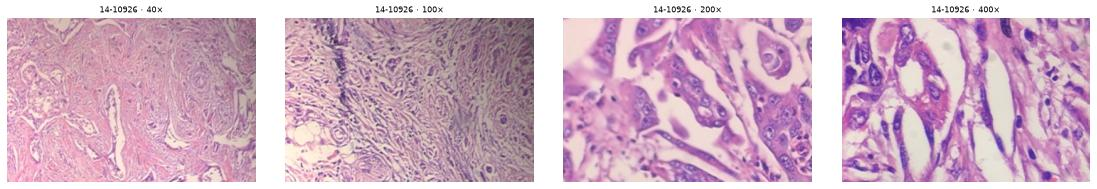

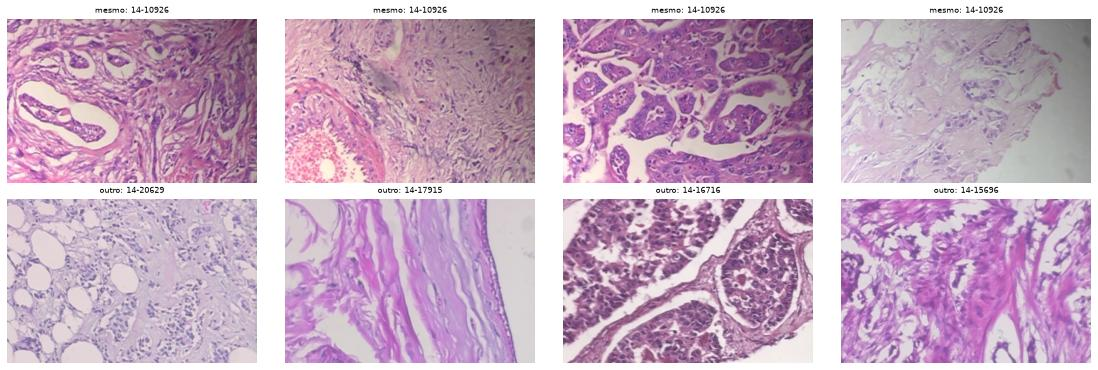

In [16]:
p0 = df[df.subtipo == "DC"].paciente.iloc[0]
um = df[df.paciente == p0].groupby("magnificacao").first().reset_index()
show(um.path.tolist(), [f"{p0} · {m}×" for m in um.magnificacao], ncols=4)

mesmo = m100[m100.paciente == p0].sample(4, random_state=0)
outros_pac = m100[(m100.subtipo == "DC") & (m100.paciente != p0)].groupby("paciente").first().sample(4, random_state=0)
show(mesmo.path.tolist() + outros_pac.path.tolist(),
     [f"mesmo: {p0}"] * 4 + [f"outro: {p}" for p in outros_pac.index], ncols=4)

## 7. Em aberto (para decisão)

- **Anomalia A:** como tratar `14-13412` (mesmas imagens como DC e LC) e as repetições dentro de `LC 14-12204`.
- **Anomalia B:** unidade de "paciente" para as divisões: pasta (`paciente`) ou número da lâmina (`caso`); e, no caso de `caso`, o que fazer com 14-21998 (F e PT) e 14-29960 (A e F).
- **k-shots e k_tst:** quais combinações da seção 5 entram na grade.